# XOR Gate using a Multilayer Perceptron (MLP)

**Architecture:** 2 input neurons → 3 neurons in one hidden layer → 1 output neuron

This notebook implements a small MLP from scratch using **NumPy**. It uses sigmoid activation in both layers, binary cross-entropy loss, and full-batch gradient descent.

We will verify that the final binary predictions are `[0, 1, 1, 0]`.

## 1. Import libraries

We use NumPy for matrix operations and Matplotlib to visualize the training loss. No deep-learning framework is used.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 2. Create the XOR dataset



In [3]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

print("X:\n", X)
print("y:\n", y)
print("X shape:", X.shape)
print("y shape:", y.shape)

assert X.shape == (4, 2)
assert y.shape == (4, 1)

X:
 [[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]
y:
 [[0.]
 [1.]
 [1.]
 [0.]]
X shape: (4, 2)
y shape: (4, 1)


## 3. Define the network architecture and initialize parameters

The network has two sets of connections:

1. Input → hidden: `W1` has shape `(2, 3)` and `b1` has shape `(1, 3)`.
2. Hidden → output: `W2` has shape `(3, 1)` and `b2` has shape `(1, 1)`.

Biases are separate from the weight matrices. We initialize weights to small random values so that hidden neurons do not all start identically. Biases start at zero.

we use Xavier initialization becuase it randomly assigns initial weights within a mathematically calculated range so that weights are neither excessively large nor excessively small.

In [4]:
input_neurons = 2
hidden_neurons = 3
output_neurons = 1

# Xavier-style uniform initialization
W1 = np.random.uniform(
    -1, 1, size=(input_neurons, hidden_neurons)
) * np.sqrt(2 / (input_neurons + hidden_neurons))

b1 = np.zeros((1, hidden_neurons))

W2 = np.random.uniform(
    -1, 1, size=(hidden_neurons, output_neurons)
) * np.sqrt(2 / (hidden_neurons + output_neurons))

b2 = np.zeros((1, output_neurons))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

assert W1.shape == (2, 3)
assert b1.shape == (1, 3)
assert W2.shape == (3, 1)
assert b2.shape == (1, 1)

W1 shape: (2, 3)
b1 shape: (1, 3)
W2 shape: (3, 1)
b2 shape: (1, 1)


## 4. Define the sigmoid activation function

Sigmoid converts each weighted sum into a value between 0 and 1. We use it in the hidden layer and output layer.

In [5]:
def sigmoid(z):
    # Clipping avoids numerical overflow in exp for very large values.
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def sigmoid_derivative_from_activation(a):
    # If a = sigmoid(z), then da/dz = a * (1 - a).
    return a * (1 - a)

## 5. Forward propagation

For all four samples at once:

1. `Z1 = X @ W1 + b1`: weighted sums entering the hidden layer.
2. `A1 = sigmoid(Z1)`: hidden-layer activations.
3. `Z2 = A1 @ W2 + b2`: weighted sum entering the output layer.
4. `A2 = sigmoid(Z2)`: predicted probabilities.

We return the intermediate values because backpropagation needs them later.

In [6]:
def forward_propagation(X, W1, b1, W2, b2):
    Z1 = X @ W1 + b1
    A1 = sigmoid(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    cache = {
        "Z1": Z1,
        "A1": A1,
        "Z2": Z2,
        "A2": A2
    }
    return A2, cache


# Check one forward pass before training
initial_predictions, cache = forward_propagation(X, W1, b1, W2, b2)

print("Z1 shape:", cache["Z1"].shape)
print("A1 shape:", cache["A1"].shape)
print("Z2 shape:", cache["Z2"].shape)
print("A2 shape:", cache["A2"].shape)
print("Initial predicted probabilities:\n", initial_predictions)

Z1 shape: (4, 3)
A1 shape: (4, 3)
Z2 shape: (4, 1)
A2 shape: (4, 1)
Initial predicted probabilities:
 [[0.50448555]
 [0.48193214]
 [0.53120288]
 [0.50890761]]


## 6. Binary cross-entropy loss

The output is a probability, so binary cross-entropy is suitable for this binary classification task.

We average the loss over the four training samples. A small epsilon prevents taking the logarithm of exactly zero.

In [ ]:
def binary_cross_entropy(y_actual, y_pred):
    epsilon = 1e-12
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_actual * np.log(y_pred)
        + (1 - y_actual) * np.log(1 - y_pred) #this is formula for binary cross entropy loss
    )
    return loss


initial_loss = binary_cross_entropy(y, initial_predictions)
print("Initial BCE loss:", initial_loss)

Initial BCE loss: 0.6939612497726922


## 7. Backpropagation

Backpropagation calculates how each weight and bias contributed to the loss.

Because we use **sigmoid output + binary cross-entropy**, the output-layer error simplifies to:

`dZ2 = (A2 - y) / m`

where `m` is the number of samples. We then propagate this error through `W2` to calculate the hidden-layer gradients.

The gradients are calculated for all four samples together.

In [9]:
def backward_propagation(X, y, W2, cache):
    m = X.shape[0]

    A1 = cache["A1"]
    A2 = cache["A2"]

    # Output layer gradients: sigmoid + binary cross-entropy
    dZ2 = (A2 - y) / m
    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Propagate the error back to the hidden layer
    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * sigmoid_derivative_from_activation(A1)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    gradients = {
        "dW1": dW1,
        "db1": db1,
        "dW2": dW2,
        "db2": db2
    }
    return gradients

## 8. Train the network using gradient descent

One epoch performs these operations in order:

1. Forward propagation.
2. Calculate loss.
3. Backpropagation.
4. Update all weights and biases.

We use full-batch gradient descent, meaning all four XOR samples are used in each update.

In [10]:
learning_rate = 1.0
epochs = 20000

loss_history = []

for epoch in range(epochs):
    # 1. Forward propagation
    predictions, cache = forward_propagation(X, W1, b1, W2, b2)

    # 2. Calculate loss
    loss = binary_cross_entropy(y, predictions)
    loss_history.append(loss)

    # 3. Backpropagation
    gradients = backward_propagation(X, y, W2, cache)

    # 4. Update parameters
    W1 -= learning_rate * gradients["dW1"]
    b1 -= learning_rate * gradients["db1"]
    W2 -= learning_rate * gradients["dW2"]
    b2 -= learning_rate * gradients["db2"]

    if (epoch + 1) % 2000 == 0:
        print(f"Epoch {epoch + 1:5d}/{epochs}, Loss: {loss:.6f}")

print("\nTraining completed.")

Epoch  2000/20000, Loss: 0.006159
Epoch  4000/20000, Loss: 0.002368
Epoch  6000/20000, Loss: 0.001454
Epoch  8000/20000, Loss: 0.001046
Epoch 10000/20000, Loss: 0.000815
Epoch 12000/20000, Loss: 0.000668
Epoch 14000/20000, Loss: 0.000565
Epoch 16000/20000, Loss: 0.000489
Epoch 18000/20000, Loss: 0.000432
Epoch 20000/20000, Loss: 0.000386

Training completed.


## 9. Plot the training loss

A downward trend indicates that the network is reducing its training loss. The plot alone is not enough to prove that XOR was learned; we also check the final predictions below.

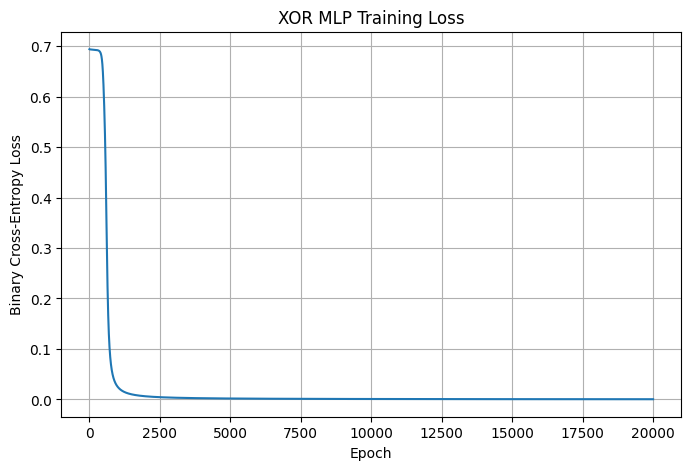

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("XOR MLP Training Loss")
plt.grid(True)
plt.show()

## 10. Evaluate the trained network

We run forward propagation using the final parameters, convert probabilities to binary predictions using a threshold of 0.5, and compare them with the XOR targets.

In [12]:
final_probabilities, final_cache = forward_propagation(X, W1, b1, W2, b2)
binary_predictions = (final_probabilities >= 0.5).astype(int)

print("Input X:")
print(X.astype(int))

print("\nActual XOR outputs:")
print(y.astype(int).ravel())

print("\nPredicted probabilities:")
print(np.round(final_probabilities, 4).ravel())

print("\nPredicted binary outputs:")
print(binary_predictions.ravel())

print("\nFinal BCE loss:", binary_cross_entropy(y, final_probabilities))

if np.array_equal(binary_predictions, y.astype(int)):
    print("\nSuccess: The network learned all four XOR cases.")
else:
    print("\nThe network has not yet matched all XOR cases. Review the training output and parameters.")

Input X:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

Actual XOR outputs:
[0 1 1 0]

Predicted probabilities:
[4.000e-04 9.995e-01 9.996e-01 3.000e-04]

Predicted binary outputs:
[0 1 1 0]

Final BCE loss: 0.00038594087557641235

Success: The network learned all four XOR cases.


## 11. Parameter and shape verification

The final check confirms that the network still has the intended architecture and parameter dimensions.

In [13]:
print("Final parameter shapes:")
print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

total_parameters = W1.size + b1.size + W2.size + b2.size
print("Total trainable parameters:", total_parameters)

assert total_parameters == 13
assert W1.shape == (2, 3)
assert b1.shape == (1, 3)
assert W2.shape == (3, 1)
assert b2.shape == (1, 1)

Final parameter shapes:
W1: (2, 3)
b1: (1, 3)
W2: (3, 1)
b2: (1, 1)
Total trainable parameters: 13
